# Virtual Try-On with Segmentation and Warping (trained on a MacBook)

**Goal:** put a new shirt on a photo of a person.

**No diffusion.** Diffusion models take days of GPU time to train. We use a classic computer vision pipeline that trains in a few hours on an Apple M4 (MPS):

1. **Segmentation model:** splits the person photo into body parts (hair, face, neck, top, arms, lower body).
2. **Warping model:** bends the flat shirt photo so it matches the body shape and pose.
3. **Try-on model:** blends the bent shirt onto the person and fills in the arms and neck.

**Data:** VITON-HD (person photos, shirt photos, shirt masks, body-part maps, pose points).

**Steps in this notebook**
1. Settings
2. Load the data
3. Data cleaning
4. Preprocessing
5. Feature selection
6. Model 1: segmentation
7. Model 2: warping
8. Model 3: try-on (8b: making it sharper)
9. Results and scores (9b: fully automatic pipeline)
10. Demo

## 1. Settings

In [1]:
import os, json, glob, time, math, random, hashlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

DATA_ROOT = '/Volumes/PNYRP60PSSD/viton/data'      # folder with train/ and test/
CACHE     = '/Volumes/PNYRP60PSSD/viton/cache'     # preprocessed arrays
OUT       = os.path.expanduser('~/virtual-tryon/run') # checkpoints, charts, results
H, W = 256, 192                                      # training size
SEG_MIN, WARP_MIN, TOM_MIN = 25, 45, 75              # training time per model, minutes
TOM2_MIN = 60                                        # extra try-on training with the GAN loss (step 8b)
ABL_MIN = 3                                          # minutes per feature set in step 5
BATCH = 8
TOM_BASE = 48                                        # width of the try-on U-Net
SEED = 0

os.makedirs(CACHE, exist_ok=True); os.makedirs(OUT, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', dev, '| torch', torch.__version__)

device: mps | torch 2.8.0


## 2. Load the data

We look for the usual VITON-HD folders. Each person photo `X.jpg` should have:
- `image/X.jpg` person photo
- `cloth/X.jpg` the same shirt as a flat product photo
- `cloth-mask/X.jpg` white where the shirt is
- `image-parse-v3/X.png` body-part label map
- `openpose_json/X_keypoints.json` pose points

In [2]:
def find_dir(split_dir, names):
    for n in names:
        p = os.path.join(split_dir, n)
        if os.path.isdir(p): return p
    return None

FOLDERS = {
    'image': ['image'],
    'cloth': ['cloth'],
    'cmask': ['cloth-mask', 'cloth_mask'],
    'parse': ['image-parse-v3', 'image-parse', 'image_parse'],
    'pose':  ['openpose_json', 'pose'],
}

def index_split(split):
    sd = os.path.join(DATA_ROOT, split)
    dirs = {k: find_dir(sd, v) for k, v in FOLDERS.items()}
    names = sorted(os.path.basename(p) for p in glob.glob(os.path.join(dirs['image'], '*.jpg')))
    rows = []
    for n in names:
        stem = os.path.splitext(n)[0]
        rows.append(dict(
            split=split, name=n,
            image=os.path.join(dirs['image'], n),
            cloth=os.path.join(dirs['cloth'], n) if dirs['cloth'] else None,
            cmask=os.path.join(dirs['cmask'], n) if dirs['cmask'] else None,
            parse=os.path.join(dirs['parse'], stem + '.png') if dirs['parse'] else None,
            pose=os.path.join(dirs['pose'], stem + '_keypoints.json') if dirs['pose'] else None))
    return pd.DataFrame(rows), dirs

frames = []
for split in ['train', 'test']:
    if os.path.isdir(os.path.join(DATA_ROOT, split)):
        df_s, dirs = index_split(split)
        print(split, len(df_s), 'photos |', {k: (os.path.basename(v) if v else None) for k, v in dirs.items()})
        frames.append(df_s)
df = pd.concat(frames, ignore_index=True)
df.head()

train 11647 photos | {'image': 'image', 'cloth': 'cloth', 'cmask': 'cloth-mask', 'parse': 'image-parse-v3', 'pose': 'openpose_json'}
test 2032 photos | {'image': 'image', 'cloth': 'cloth', 'cmask': 'cloth-mask', 'parse': 'image-parse-v3', 'pose': 'openpose_json'}


,split,name,image,cloth,cmask,parse,pose
0,train,00000_00.jpg,/Volumes/PNYRP60PSSD/viton/data/train/image/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth-ma...,/Volumes/PNYRP60PSSD/viton/data/train/image-pa...,/Volumes/PNYRP60PSSD/viton/data/train/openpose...
1,train,00001_00.jpg,/Volumes/PNYRP60PSSD/viton/data/train/image/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth-ma...,/Volumes/PNYRP60PSSD/viton/data/train/image-pa...,/Volumes/PNYRP60PSSD/viton/data/train/openpose...
2,train,00002_00.jpg,/Volumes/PNYRP60PSSD/viton/data/train/image/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth-ma...,/Volumes/PNYRP60PSSD/viton/data/train/image-pa...,/Volumes/PNYRP60PSSD/viton/data/train/openpose...
3,train,00003_00.jpg,/Volumes/PNYRP60PSSD/viton/data/train/image/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth-ma...,/Volumes/PNYRP60PSSD/viton/data/train/image-pa...,/Volumes/PNYRP60PSSD/viton/data/train/openpose...
4,train,00005_00.jpg,/Volumes/PNYRP60PSSD/viton/data/train/image/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth/00...,/Volumes/PNYRP60PSSD/viton/data/train/cloth-ma...,/Volumes/PNYRP60PSSD/viton/data/train/image-pa...,/Volumes/PNYRP60PSSD/viton/data/train/openpose...


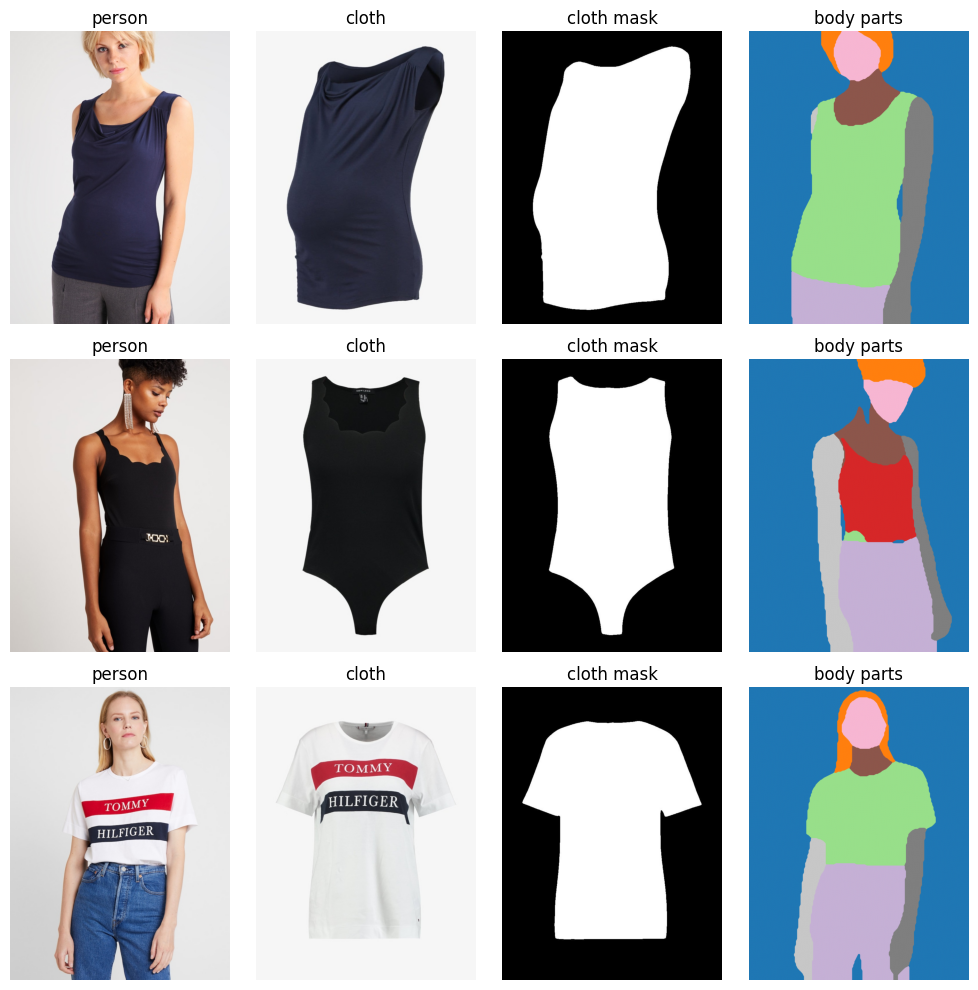

In [3]:
# look at a few raw examples
ex = df.sample(3, random_state=SEED)
fig, ax = plt.subplots(3, 4, figsize=(10, 10))
for i, (_, r) in enumerate(ex.iterrows()):
    ax[i, 0].imshow(Image.open(r.image)); ax[i, 0].set_title('person')
    ax[i, 1].imshow(Image.open(r.cloth)); ax[i, 1].set_title('cloth')
    ax[i, 2].imshow(Image.open(r.cmask), cmap='gray'); ax[i, 2].set_title('cloth mask')
    ax[i, 3].imshow(np.array(Image.open(r.parse)), cmap='tab20', vmin=0, vmax=19); ax[i, 3].set_title('body parts')
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 3. Data cleaning

Checks on every photo:
1. **Missing files:** any of the 5 files is missing.
2. **Broken images:** the file will not open.
3. **Wrong size:** not 4:3 (height:width).
4. **Bad cloth mask:** almost empty or almost full.
5. **No shirt on the person:** the top region in the body-part map is too small.
6. **Bad pose:** neck or shoulders not found.
7. **Duplicate shirts:** the same shirt photo appears twice (checked with a small colour thumbnail hash).
8. **Leakage:** a test shirt also appears in train.

We drop the bad rows and keep a table of why each one was dropped.

In [4]:
UPPER = [5, 6, 7]                # top, dress, coat in the label map

def ahash(img):  # small colour thumbnail, 16 levels per channel: same hash = same shirt photo
    g = np.asarray(img.convert('RGB').resize((24, 32), Image.BILINEAR)) // 16
    return hashlib.md5(g.tobytes()).hexdigest()

def read_pose(path):
    d = json.load(open(path))
    if not d.get('people'): return None
    k = np.array(d['people'][0]['pose_keypoints_2d'], np.float32).reshape(-1, 3)
    return k

def check_row(r):
    issues = []
    for k in ['image', 'cloth', 'cmask', 'parse', 'pose']:
        if r[k] is None or not os.path.exists(r[k]): issues.append('missing_' + k)
    if issues: return issues, None
    try:
        im = Image.open(r.image); im.load(); cl = Image.open(r.cloth); cl.load()
        cm = np.asarray(Image.open(r.cmask).convert('L')); pa = np.asarray(Image.open(r.parse))
    except Exception:
        return ['broken_file'], None
    w, h = im.size
    if abs(h / w - 4 / 3) > 0.02: issues.append('wrong_ratio')
    if pa.ndim != 2: issues.append('parse_not_labels')
    mfrac = (cm > 127).mean()
    if mfrac < 0.05 or mfrac > 0.95: issues.append('bad_cloth_mask')
    if pa.ndim == 2 and np.isin(pa, UPPER).mean() < 0.02: issues.append('no_top_on_person')
    k = read_pose(r.pose)
    if k is None: issues.append('no_pose')
    elif (k[[1, 2, 5], 2] < 0.05).any(): issues.append('bad_pose')
    return issues, ahash(cl)

t0 = time.time()
res = [check_row(r) for _, r in df.iterrows()]
df['issues'] = [', '.join(i) for i, _ in res]
df['cloth_hash'] = [h for _, h in res]
print(f'checked {len(df)} rows in {time.time()-t0:.0f}s')

checked 13679 rows in 133s


In [5]:
# duplicates inside each split, and leakage from test into train
dup = df[df.cloth_hash.notna()].duplicated(['split', 'cloth_hash'], keep='first')
df.loc[dup[dup].index, 'issues'] = df.loc[dup[dup].index, 'issues'].str.cat(['duplicate_cloth'] * dup.sum(), sep=', ').str.strip(', ')
train_hashes = set(df[df.split == 'train'].cloth_hash)
leak = (df.split == 'test') & df.cloth_hash.isin(train_hashes)
df.loc[leak, 'issues'] = df.loc[leak, 'issues'].str.cat(['in_train_too'] * leak.sum(), sep=', ').str.strip(', ')

report = (df.assign(issue=df.issues.str.split(', ')).explode('issue')
            .query('issue != ""').groupby(['split', 'issue']).size().unstack(0).fillna(0).astype(int))
display(report)
clean = df[df.issues == ''].reset_index(drop=True)
summary = df.groupby('split').size().to_frame('before').join(clean.groupby('split').size().to_frame('after'))
summary['dropped'] = summary.before - summary.after
display(summary)
df.to_csv(f'{OUT}/cleaning_log.csv', index=False)

split,test,train
issue,,
bad_cloth_mask,2,70
duplicate_cloth,6,94
in_train_too,37,0
no_top_on_person,3,11


,before,after,dropped
split,,,
test,2032,1984,48
train,11647,11473,174


## 4. Preprocessing

For each clean row we:
- resize everything to **256×192**,
- merge the 20 body-part labels into **8 simple classes**,
- turn the cloth mask into 0/1,
- keep 18 pose points in pixel units, with confidence.

Everything is saved once as numpy arrays on the SSD, so training reads fast and never decodes JPEGs again.

In [6]:
CLASSES = ['background', 'hair', 'face', 'neck', 'top', 'lower body', 'left arm', 'right arm']
LUT = np.zeros(256, np.uint8)
for src, dst in {1: 1, 2: 1, 4: 2, 13: 2, 10: 3, 5: 4, 6: 4, 7: 4,
                 8: 5, 9: 5, 12: 5, 16: 5, 17: 5, 18: 5, 19: 5, 14: 6, 15: 7}.items():
    LUT[src] = dst
NC = len(CLASSES)
NK = 18

def prep_row(r):
    im = np.asarray(Image.open(r.image).convert('RGB').resize((W, H), Image.BICUBIC))
    cl = np.asarray(Image.open(r.cloth).convert('RGB').resize((W, H), Image.BICUBIC))
    cm = (np.asarray(Image.open(r.cmask).convert('L').resize((W, H), Image.NEAREST)) > 127).astype(np.uint8)
    pa = LUT[np.asarray(Image.open(r.parse).resize((W, H), Image.NEAREST))]
    k = read_pose(r.pose)[:NK].copy()
    ow, oh = Image.open(r.image).size
    k[:, 0] *= W / ow; k[:, 1] *= H / oh
    return im, cl, cm, pa, k

def build_cache(split):
    sub = clean[clean.split == split].reset_index(drop=True)
    n = len(sub); base = f'{CACHE}/{split}'
    if os.path.exists(base + '_done.txt') and int(open(base + '_done.txt').read()) == n:
        print(split, 'cache ready'); return
    arr = {k: np.lib.format.open_memmap(f'{base}_{k}.npy', 'w+', np.uint8, s) for k, s in
           [('person', (n, H, W, 3)), ('cloth', (n, H, W, 3)), ('cmask', (n, H, W)), ('parse', (n, H, W))]}
    pose = np.zeros((n, NK, 3), np.float32)
    t0 = time.time()
    for i, r in sub.iterrows():
        arr['person'][i], arr['cloth'][i], arr['cmask'][i], arr['parse'][i], pose[i] = prep_row(r)
        if i % 2000 == 0: print(f'{split} {i}/{n}  {time.time()-t0:.0f}s')
    for a in arr.values(): a.flush()
    np.save(f'{base}_pose.npy', pose); sub.name.to_csv(f'{base}_names.csv', index=False)
    open(base + '_done.txt', 'w').write(str(n))
    print(split, 'done', n, f'{time.time()-t0:.0f}s')

for s in clean.split.unique(): build_cache(s)

def load_split(split):
    base = f'{CACHE}/{split}'
    d = {k: np.load(f'{base}_{k}.npy', mmap_mode='r') for k in ['person', 'cloth', 'cmask', 'parse']}
    d['pose'] = np.load(f'{base}_pose.npy'); d['names'] = pd.read_csv(f'{base}_names.csv').name.tolist()
    return d

TR, TE = load_split('train'), load_split('test')
# hold out 5% of train for validation
idx = np.random.RandomState(SEED).permutation(len(TR['names']))
VAL_IDX, TR_IDX = idx[:max(8, len(idx) // 20)], idx[max(8, len(idx) // 20):]
print('train', len(TR_IDX), '| val', len(VAL_IDX), '| test', len(TE['names']))

train cache ready
test cache ready
train 10900 | val 573 | test 1984


### Build the inputs (features) on the GPU

From the person photo, body-part map and pose we can build these candidate inputs. None of them show the shirt the person is wearing, so the model cannot cheat:

| name | channels | what it is |
|---|---|---|
| `agnostic` | 3 | person photo with the top, arms and neck greyed out |
| `shape` | 1 | blurry body outline (tells size, not shirt details) |
| `head` | 3 | only the face and hair pixels |
| `pose` | 18 | one small heat spot per body joint |
| `keep_parts` | 4 | maps of background, hair, face, lower body |

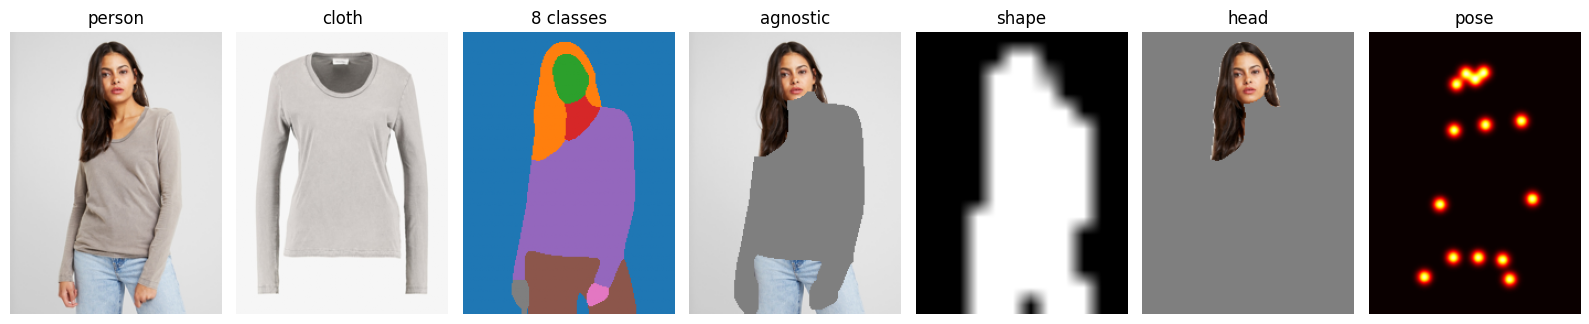

In [7]:
def to_t(x):  # uint8 numpy -> float tensor on device
    return torch.from_numpy(np.ascontiguousarray(x)).to(dev)

def onehot(parse):  # (B,H,W) long -> (B,NC,H,W)
    return F.one_hot(parse.long(), NC).permute(0, 3, 1, 2).float().contiguous()

def pose_maps(k, sigma=4.0):
    B = k.shape[0]
    ys = torch.arange(H, device=dev).view(1, 1, H, 1).float()
    xs = torch.arange(W, device=dev).view(1, 1, 1, W).float()
    x, y, c = k[..., 0].view(B, NK, 1, 1), k[..., 1].view(B, NK, 1, 1), k[..., 2].view(B, NK, 1, 1)
    return torch.exp(-((xs - x) ** 2 + (ys - y) ** 2) / (2 * sigma ** 2)) * (c > 0.05).float()

def make_batch(D, ids):
    ids = np.asarray(ids)
    person = (to_t(D['person'][ids]).permute(0, 3, 1, 2).float() / 127.5 - 1).contiguous()
    cloth = (to_t(D['cloth'][ids]).permute(0, 3, 1, 2).float() / 127.5 - 1).contiguous()
    cmask = to_t(D['cmask'][ids]).unsqueeze(1).float()
    parse = to_t(D['parse'][ids]).long()
    oh = onehot(parse)
    top = oh[:, 4:5]
    remove = (oh[:, 3:5].sum(1, keepdim=True) + oh[:, 6:8].sum(1, keepdim=True)).clamp(0, 1)
    remove = F.max_pool2d(remove, 7, 1, 3)                         # grow the grey area a bit
    body = 1 - oh[:, 0:1]
    shape = F.interpolate(F.interpolate(body, (H // 16, W // 16), mode='bilinear'), (H, W), mode='bilinear') * 2 - 1
    head_m = oh[:, 1:3].sum(1, keepdim=True)
    feats = {
        'agnostic': person * (1 - remove),
        'shape': shape,
        'head': person * head_m,
        'pose': pose_maps(to_t(D['pose'][ids]).float()),
        'keep_parts': torch.cat([oh[:, 0:1], oh[:, 1:3].sum(1, keepdim=True), oh[:, 2:3], oh[:, 5:6]], 1),
    }
    return dict(person=person, cloth=cloth, cmask=cmask, parse=parse, top=top, keep=1 - remove, feats=feats)

FEAT_CH = {'agnostic': 3, 'shape': 1, 'head': 3, 'pose': NK, 'keep_parts': 4}
def stack(b, names): return torch.cat([b['feats'][n] for n in names], 1)

b = make_batch(TR, TR_IDX[:4])
show = lambda t: ((t.permute(1, 2, 0).cpu().numpy() + 1) / 2).clip(0, 1)
fig, ax = plt.subplots(1, 7, figsize=(16, 3.5))
ax[0].imshow(show(b['person'][0])); ax[0].set_title('person')
ax[1].imshow(show(b['cloth'][0])); ax[1].set_title('cloth')
ax[2].imshow(b['parse'][0].cpu(), cmap='tab10', vmin=0, vmax=9); ax[2].set_title('8 classes')
ax[3].imshow(show(b['feats']['agnostic'][0])); ax[3].set_title('agnostic')
ax[4].imshow(b['feats']['shape'][0, 0].cpu(), cmap='gray'); ax[4].set_title('shape')
ax[5].imshow(show(b['feats']['head'][0])); ax[5].set_title('head')
ax[6].imshow(b['feats']['pose'][0].sum(0).cpu(), cmap='hot'); ax[6].set_title('pose')
for a in ax: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/features.png', dpi=120); plt.show()

## Models

**Warping model (appearance flow).** A CNN looks at the person inputs and the flat shirt together and predicts, for every pixel, where to take the shirt colour from. It works coarse to fine: first a rough flow at 8×6, then refined at 16×12, 32×24 and 64×48. This idea comes from PF-AFN and GP-VTON, the strongest non-diffusion try-on methods. A smoothness loss stops the shirt from tearing. A VGG loss makes the bent shirt keep its pattern.

**Try-on model.** A U-Net gets the person inputs plus the bent shirt. It outputs a rough person image and a blend mask. Final image = mask × bent shirt + (1 − mask) × rough image. This keeps the shirt's real texture and lets the network paint skin and arms.

In [8]:
def conv(ci, co, s=1):
    return nn.Sequential(nn.Conv2d(ci, co, 3, s, 1), nn.InstanceNorm2d(co, affine=True), nn.LeakyReLU(0.2, True))

def sample(img, grid):
    # bilinear sampling written with gather, because grid_sample has no backward pass on MPS
    # grid: (B,H,W,2) with x,y in [-1,1]; outside the image = 0
    B, C, Hi, Wi = img.shape
    x = (grid[..., 0] + 1) * (Wi - 1) / 2; y = (grid[..., 1] + 1) * (Hi - 1) / 2
    x0, y0 = x.floor().detach(), y.floor().detach()
    wx, wy = x - x0, y - y0
    flat = img.reshape(B, C, -1)
    def at(xi, yi):
        ok = ((xi >= 0) & (xi <= Wi - 1) & (yi >= 0) & (yi <= Hi - 1)).float().unsqueeze(1)
        idx = (yi.clamp(0, Hi - 1) * Wi + xi.clamp(0, Wi - 1)).long().reshape(B, 1, -1).expand(-1, C, -1)
        return flat.gather(2, idx).reshape(B, C, *xi.shape[1:]) * ok
    return (at(x0, y0) * ((1 - wx) * (1 - wy)).unsqueeze(1) + at(x0 + 1, y0) * (wx * (1 - wy)).unsqueeze(1) +
            at(x0, y0 + 1) * ((1 - wx) * wy).unsqueeze(1) + at(x0 + 1, y0 + 1) * (wx * wy).unsqueeze(1))

MEAN = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.IMAGENET1K_V1).features[:23].to(dev).eval()
for p in vgg.parameters(): p.requires_grad_(False)
VGG_LAYERS = [3, 8, 15, 22]
def vgg_loss(x, y):  # perceptual loss: compare VGG16 features instead of raw pixels
    x = ((x + 1) / 2 - MEAN) / STD; y = ((y + 1) / 2 - MEAN) / STD; l = 0
    for i, layer in enumerate(vgg):
        x, y = layer(x), layer(y)
        if i in VGG_LAYERS: l = l + (x - y).abs().mean()
        if i == VGG_LAYERS[-1]: break
    return l

class WarpNet(nn.Module):
    # coarse-to-fine appearance flow (idea from PF-AFN / GP-VTON):
    # predict a flow at 1/32 size, then refine it at 1/16, 1/8 and 1/4 size
    def __init__(self, cin):
        super().__init__()
        ch = [cin + 4, 64, 128, 256, 256, 256]
        self.down = nn.ModuleList([nn.Sequential(conv(ch[i], ch[i + 1], 2), conv(ch[i + 1], ch[i + 1])) for i in range(5)])
        self.up = nn.ModuleList([nn.Sequential(conv(256 + 256 + 2, 256), conv(256, 128)),
                                 nn.Sequential(conv(128 + 256 + 2, 128), conv(128, 64)),
                                 nn.Sequential(conv(64 + 128 + 2, 64), conv(64, 32))])
        self.flow0 = nn.Conv2d(256, 2, 3, 1, 1)
        self.heads = nn.ModuleList([nn.Conv2d(c, 2, 3, 1, 1) for c in [128, 64, 32]])
        for h in [self.flow0, *self.heads]: nn.init.zeros_(h.weight); nn.init.zeros_(h.bias)
        ys, xs = torch.meshgrid(torch.linspace(-1, 1, H), torch.linspace(-1, 1, W), indexing='ij')
        self.register_buffer('base', torch.stack([xs, ys], -1).unsqueeze(0))

    def forward(self, person_in, cloth, cmask):
        x = torch.cat([person_in, cloth, cmask], 1); skips = []
        for d in self.down: x = d(x); skips.append(x)          # 128x96 ... 8x6
        flows = [self.flow0(x)]                                # flow at 8x6
        for up, head, skip in zip(self.up, self.heads, [skips[3], skips[2], skips[1]]):
            f = F.interpolate(flows[-1], skip.shape[2:], mode='bilinear', align_corners=True)
            x = up(torch.cat([F.interpolate(x, skip.shape[2:], mode='bilinear'), skip, f], 1))
            flows.append(f + head(x))                          # refine
        flow = F.interpolate(flows[-1], (H, W), mode='bilinear', align_corners=True).permute(0, 2, 3, 1)
        grid = self.base + flow
        wc = sample(cloth - 1, grid) + 1   # outside the shirt photo = white
        wm = sample(cmask, grid)
        return wc, wm, flows

def smooth_loss(flows):  # second-order smoothness on every flow level: no tearing
    l = 0
    for f in flows:
        if f.shape[2] < 3 or f.shape[3] < 3: continue
        dx = f[:, :, :, 2:] - 2 * f[:, :, :, 1:-1] + f[:, :, :, :-2]
        dy = f[:, :, 2:] - 2 * f[:, :, 1:-1] + f[:, :, :-2]
        l = l + dx.abs().mean() + dy.abs().mean()
    return l

def warp_losses(net, b, names, perceptual=True):
    wc, wm, flows = net(stack(b, names), b['cloth'], b['cmask'])
    top = b['top']
    l_rgb = ((wc - b['person']).abs() * top).sum() / (top.sum() * 3 + 1)
    l_mask = (wm - top).abs().mean()
    l = l_rgb + 2 * l_mask + 2 * smooth_loss(flows)
    if perceptual: l = l + 0.2 * vgg_loss(wc * top + (1 - top), b['person'] * top + (1 - top))
    return l, wc, wm

def iou(a, b_):
    a, b_ = a > 0.5, b_ > 0.5
    return ((a & b_).sum((1, 2, 3)).float() / ((a | b_).sum((1, 2, 3)).float() + 1)).cpu()

class UNet(nn.Module):
    def __init__(self, cin, cout, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 8]
        self.inc = nn.Sequential(conv(cin, c[0]), conv(c[0], c[0]))
        self.down = nn.ModuleList([nn.Sequential(conv(c[i], c[i + 1], 2), conv(c[i + 1], c[i + 1])) for i in range(4)])
        self.up = nn.ModuleList([nn.Sequential(conv(c[i + 1] + c[i], c[i]), conv(c[i], c[i])) for i in reversed(range(4))])
        self.out = nn.Conv2d(c[0], cout, 1)

    def forward(self, x):
        skips = [self.inc(x)]
        for d in self.down: skips.append(d(skips[-1]))
        y = skips.pop()
        for u in self.up:
            s = skips.pop()
            y = u(torch.cat([F.interpolate(y, s.shape[2:], mode='bilinear'), s], 1))
        return self.out(y)

def n_params(m): return f'{sum(p.numel() for p in m.parameters()) / 1e6:.1f}M'

In [9]:
# shared training loop: trains for a fixed number of minutes, saves checkpoints, can resume
import gc
def free_memory():  # give cached GPU memory back (16 GB Mac shares RAM with the GPU)
    gc.collect()
    if dev.type == 'mps': torch.mps.empty_cache()

def train_for(name, model, step_fn, val_fn, minutes, lr=2e-4, val_every=200, force=False, sched=None):
    path = f'{OUT}/{name}.pt'
    opt = torch.optim.Adam(model.parameters(), lr=lr, betas=(0.5, 0.999))
    hist, used = [], 0.0
    if os.path.exists(path):
        ck = torch.load(path, map_location=dev)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); hist, used = ck['hist'], ck['minutes']
        if ck.get('done') and not force:
            print(f'{name}: already trained ({used:.0f} min). Loaded.'); return hist
        print(f'{name}: resuming at {used:.1f} min')
    model.train(); t0 = time.time() - used * 60; step = len(hist) * val_every; run = []
    def save(done=False):
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), hist=hist,
                        minutes=(time.time() - t0) / 60, done=done), path)
    while (time.time() - t0) / 60 < minutes:
        if sched:  # learning rate as a function of how far we are (0..1)
            for g in opt.param_groups: g['lr'] = lr * sched((time.time() - t0) / 60 / minutes)
        loss = step_fn(np.random.choice(TR_IDX, BATCH, replace=False))
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        run.append(loss.item()); step += 1
        if step % val_every == 0:
            model.eval()
            with torch.no_grad(): v = val_fn()
            model.train()
            hist.append(dict(step=step, minutes=(time.time() - t0) / 60, train_loss=float(np.mean(run)), **v)); run = []
            print(f"{name} step {step} | {hist[-1]['minutes']:.1f} min | train {hist[-1]['train_loss']:.4f} | " +
                  ' | '.join(f'{k} {v_:.4f}' for k, v_ in v.items()), flush=True)
            save()
    save(done=True); model.eval(); free_memory()
    print(f'{name}: finished, {step} steps'); return hist

def batches(D, ids, bs=16):
    for i in range(0, len(ids), bs): yield ids[i:i + bs]

## 5. Feature selection

Which person inputs should the warping model get? We train a small warping model for a few minutes with each candidate set and score it on validation photos. The score is **IoU**: how well the bent shirt mask overlaps the real shirt area on the person (1.0 = perfect).

We also score the **unbent shirt** as a baseline: what you get with no model at all.

no warp (baseline) IoU: 0.375


,features,channels,val_loss,val_iou
0,F: agnostic + parts (no pose),7,0.374455,0.788678
1,E: agnostic + shape + pose + parts,26,0.376359,0.783888
2,A: agnostic,3,0.407915,0.770183
3,D: agnostic + shape + pose,22,0.389199,0.760572
4,C: shape + head + pose,22,0.466815,0.677164
5,B: shape + pose,19,0.460226,0.674126
6,no warp (baseline),0,NaN,0.374834


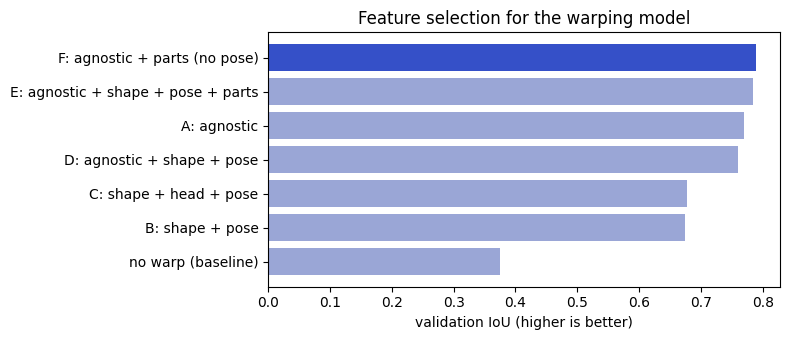

selected features: F: agnostic + parts (no pose) -> ['agnostic', 'keep_parts']


In [10]:
CANDIDATES = {
    'A: agnostic': ['agnostic'],
    'B: shape + pose': ['shape', 'pose'],
    'C: shape + head + pose': ['shape', 'head', 'pose'],
    'D: agnostic + shape + pose': ['agnostic', 'shape', 'pose'],
    'E: agnostic + shape + pose + parts': ['agnostic', 'shape', 'pose', 'keep_parts'],
    'F: agnostic + parts (no pose)': ['agnostic', 'keep_parts'],
}
VAL_SMALL = VAL_IDX[:min(256, len(VAL_IDX))]

def warp_val(net, names, ids=VAL_SMALL):
    ious, losses = [], []
    for bi in batches(TR, ids):
        b = make_batch(TR, bi)
        l, wc, wm = warp_losses(net, b, names, perceptual=False)
        ious.append(iou(wm, b['top'])); losses.append(l.item())
    return dict(val_loss=float(np.mean(losses)), val_iou=float(torch.cat(ious).mean()))

base_iou = []
for bi in batches(TR, VAL_SMALL):
    b = make_batch(TR, bi); base_iou.append(iou(b['cmask'], b['top']))
print('no warp (baseline) IoU:', round(float(torch.cat(base_iou).mean()), 3))

abl_path = f'{OUT}/feature_selection.csv'
if os.path.exists(abl_path):
    abl = pd.read_csv(abl_path)
else:
    rows = []
    for label, names in CANDIDATES.items():
        torch.manual_seed(SEED)
        net = WarpNet(sum(FEAT_CH[n] for n in names)).to(dev)
        tag = 'abl_' + label.split(':')[0]
        if os.path.exists(f'{OUT}/{tag}.pt'): os.remove(f'{OUT}/{tag}.pt')
        h = train_for(tag, net, lambda ids: warp_losses(net, make_batch(TR, ids), names, perceptual=False)[0],
                      lambda: warp_val(net, names), ABL_MIN, val_every=50)
        r = warp_val(net, names); rows.append(dict(features=label, channels=sum(FEAT_CH[n] for n in names), **r))
        os.remove(f'{OUT}/{tag}.pt'); del net; free_memory()
    abl = pd.DataFrame(rows)
    abl.loc[len(abl)] = dict(features='no warp (baseline)', channels=0, val_loss=np.nan,
                             val_iou=float(torch.cat(base_iou).mean()))
    abl.to_csv(abl_path, index=False)
abl = abl.sort_values('val_iou', ascending=False).reset_index(drop=True)
display(abl)
plt.figure(figsize=(8, 3.5)); plt.barh(abl.features, abl.val_iou, color=['#3550C8'] + ['#9AA6D6'] * (len(abl) - 1))
plt.gca().invert_yaxis(); plt.xlabel('validation IoU (higher is better)'); plt.title('Feature selection for the warping model')
plt.tight_layout(); plt.savefig(f'{OUT}/feature_selection.png', dpi=120); plt.show()

best_label = abl[abl.channels > 0].iloc[0].features
FEATS = CANDIDATES[best_label]
print('selected features:', best_label, '->', FEATS)

## 6. Model 1: segmentation (body parts)

A **LR-ASPP MobileNetV3** network. The backbone starts from ImageNet weights (transfer learning), and the head learns our 8 classes. Loss: cross-entropy. Score: mean IoU over classes.

This model lets the system work on a new photo that has no label map.

In [11]:
seg = torchvision.models.segmentation.lraspp_mobilenet_v3_large(
    weights=None, weights_backbone=torchvision.models.MobileNet_V3_Large_Weights.IMAGENET1K_V1, num_classes=NC).to(dev)
def seg_forward(person): return seg(((person + 1) / 2 - MEAN) / STD)['out']
print('segmentation params:', n_params(seg))

def seg_step(ids):
    b = make_batch(TR, ids)
    return F.cross_entropy(seg_forward(b['person']), b['parse'])

def seg_miou(D, ids):
    inter = torch.zeros(NC); union = torch.zeros(NC); losses = []
    for bi in batches(D, ids):
        b = make_batch(D, bi); out = seg_forward(b['person'])
        losses.append(F.cross_entropy(out, b['parse']).item())
        p, t = out.argmax(1), b['parse']
        for c in range(NC):
            inter[c] += ((p == c) & (t == c)).sum().item(); union[c] += ((p == c) | (t == c)).sum().item()
    per = (inter / union.clamp(min=1)).numpy()
    return float(np.mean(losses)), per

seg_hist = train_for('seg', seg, seg_step, lambda: dict(zip(['val_loss', 'val_miou'],
                     (lambda r: (r[0], float(r[1].mean())))(seg_miou(TR, VAL_SMALL)))), SEG_MIN, lr=1e-3)

segmentation params: 3.2M


seg: already trained (25 min). Loaded.


## 7. Model 2: warping (with the selected features)

The same warping model as in step 5, now trained longer with the selected inputs.

In [12]:
torch.manual_seed(SEED)
warp = WarpNet(sum(FEAT_CH[n] for n in FEATS)).to(dev)
print('warp params:', n_params(warp))
warp_hist = train_for('warp', warp, lambda ids: warp_losses(warp, make_batch(TR, ids), FEATS)[0],
                      lambda: warp_val(warp, FEATS), WARP_MIN)

warp params: 5.7M
warp: already trained (45 min). Loaded.


## 8. Model 3: try-on

Inputs: the selected person features + bent shirt + bent shirt mask.

Loss:
- **L1** between output and real photo (colours right),
- **perceptual loss** with a frozen VGG16 (textures and edges look right),
- **mask loss** so the blend mask follows the bent shirt.

In [13]:
tom = UNet(sum(FEAT_CH[n] for n in FEATS) + 4, 4, base=TOM_BASE).to(dev)
print('try-on params:', n_params(tom))
for p in warp.parameters(): p.requires_grad_(False)

def tryon(b):
    with torch.no_grad():
        wc, wm, _ = warp(stack(b, FEATS), b['cloth'], b['cmask'])
    out = tom(torch.cat([stack(b, FEATS), wc, wm], 1))
    rough, m = torch.tanh(out[:, :3]), torch.sigmoid(out[:, 3:4])
    final = m * wc + (1 - m) * rough
    return final, rough, m, wc, wm

def tom_step(ids):
    b = make_batch(TR, ids); final, rough, m, wc, wm = tryon(b)
    return (final - b['person']).abs().mean() + vgg_loss(final, b['person']) + (m - wm * b['top']).abs().mean()

def tom_val():
    l1 = []
    for bi in batches(TR, VAL_SMALL[:64]):
        b = make_batch(TR, bi); l1.append((tryon(b)[0] - b['person']).abs().mean().item())
    return dict(val_l1=float(np.mean(l1)))

tom_hist = train_for('tom', tom, tom_step, tom_val, TOM_MIN, val_every=100)

try-on params: 11.0M


tom: already trained (75 min). Loaded.


## 8b. Making the try-on sharper

The first scores showed one weak point: **LPIPS** was 0.131, while published methods get about 0.06. The results were a bit blurry. Two fixes:

1. **Keep the known pixels.** A new shirt does not change the face, hair, legs or background, and those pixels are already in the input. So the final image takes them straight from the photo (with a soft edge), and the network only paints the shirt area. Mask-based try-on methods do the same.
2. **Adversarial (GAN) loss.** A second network, a **PatchGAN discriminator** (as in pix2pix and VITON-HD), looks at small patches and learns to tell real photos from our results. The try-on network is trained to fool it. This pushes it toward sharp detail instead of a safe blur. Spectral norm and hinge loss keep the training stable.

We continue from the trained try-on model, lower the learning rate over time, and keep the checkpoint with the **best validation LPIPS**. Validation photos come from the train split, so the test set stays unseen.

In [14]:
import lpips
lp = lpips.LPIPS(net='alex', verbose=False).to(dev).eval()
for p in lp.parameters(): p.requires_grad_(False)

def paste_known(b, img):  # take face, hair, legs and background from the input photo
    keep = -F.max_pool2d(-b['keep'], 7, 1, 3)   # shrink by 3 px, so no old-shirt pixels come in
    keep = F.avg_pool2d(keep, 7, 1, 3)          # soft edge
    return keep * b['person'] + (1 - keep) * img

def val_scores(fn, ids=VAL_IDX[:192]):
    l1, lps = [], []
    with torch.no_grad():
        for bi in batches(TR, ids):
            b = make_batch(TR, bi); out = fn(b)
            l1.append((out - b['person']).abs().mean((1, 2, 3)).cpu()); lps.append(lp(out, b['person']).view(-1).cpu())
    return dict(val_l1=float(torch.cat(l1).mean()), val_lpips=float(torch.cat(lps).mean()))

if 'tryon_v1' not in globals(): tryon_v1 = tryon   # model 3 as trained in step 8
tom.load_state_dict(torch.load(f'{OUT}/tom.pt', map_location=dev)['model'])
steps = {'1. try-on from step 8': val_scores(lambda b: tryon_v1(b)[0]),
         '2. + keep known pixels': val_scores(lambda b: paste_known(b, tryon_v1(b)[0]))}
display(pd.DataFrame(steps).T.round(4))

/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


,val_l1,val_lpips
1. try-on from step 8,0.0765,0.1338
2. + keep known pixels,0.0588,0.1322


discriminator params: 2.8M
tom_gan: already trained (60 min). Loaded.


,val_l1,val_lpips
1. try-on from step 8,0.0765,0.1338
2. + keep known pixels,0.0588,0.1322
3. + GAN loss and longer training (best checkpoint),0.0523,0.1140


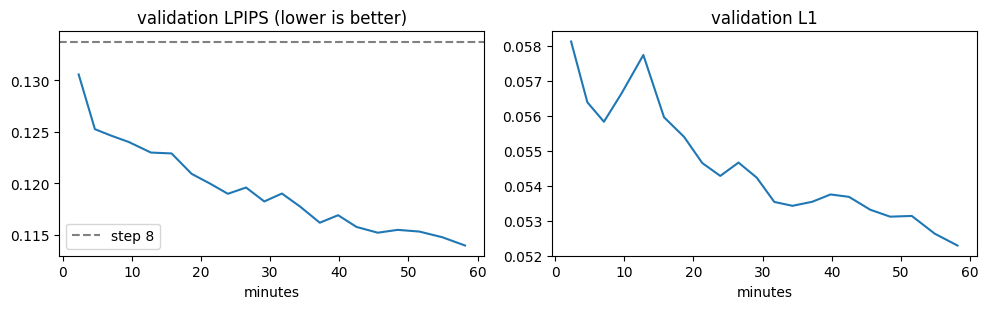

In [15]:
class PatchD(nn.Module):  # PatchGAN: one real/fake score per image patch
    def __init__(self, cin, base=64):
        super().__init__()
        sn = nn.utils.spectral_norm
        self.net = nn.Sequential(
            sn(nn.Conv2d(cin, base, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(base, base * 2, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(base * 2, base * 4, 4, 2, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(base * 4, base * 8, 4, 1, 1)), nn.LeakyReLU(0.2, True),
            sn(nn.Conv2d(base * 8, 1, 4, 1, 1)))
    def forward(self, x): return self.net(x)

torch.manual_seed(SEED)
disc = PatchD(sum(FEAT_CH[n] for n in FEATS) + 3).to(dev)   # sees the person inputs + an image
d_opt = torch.optim.Adam(disc.parameters(), lr=4e-4, betas=(0.5, 0.999))
D_PATH, BEST = f'{OUT}/tom_gan_disc.pt', f'{OUT}/tom_best.pt'
if os.path.exists(D_PATH):
    ck = torch.load(D_PATH, map_location=dev); disc.load_state_dict(ck['model']); d_opt.load_state_dict(ck['opt'])
GAN_W = 0.1
print('discriminator params:', n_params(disc))

def tryon(b):  # version 2: same model, known pixels pasted back
    final, rough, m, wc, wm = tryon_v1(b)
    return paste_known(b, final), rough, m, wc, wm

def gan_step(ids):
    b = make_batch(TR, ids); final, rough, m, wc, wm = tryon(b)
    cond = stack(b, FEATS)
    # a) discriminator: real photo -> high score, our result -> low score
    for p in disc.parameters(): p.requires_grad_(True)
    d_loss = (F.relu(1 - disc(torch.cat([cond, b['person']], 1))).mean() +
              F.relu(1 + disc(torch.cat([cond, final.detach()], 1))).mean())
    d_opt.zero_grad(set_to_none=True); d_loss.backward(); d_opt.step()
    # b) try-on network: same losses as before + fool the discriminator
    for p in disc.parameters(): p.requires_grad_(False)
    g_adv = -disc(torch.cat([cond, final], 1)).mean()
    return ((final - b['person']).abs().mean() + vgg_loss(final, b['person']) +
            (m - wm * b['top']).abs().mean() + GAN_W * g_adv)

def gan_val():
    v = val_scores(lambda b: tryon(b)[0])
    torch.save(dict(model=disc.state_dict(), opt=d_opt.state_dict()), D_PATH)
    best = torch.load(BEST, map_location='cpu')['val_lpips'] if os.path.exists(BEST) else steps['2. + keep known pixels']['val_lpips']
    if v['val_lpips'] < best:
        torch.save(dict(model=tom.state_dict(), val_lpips=v['val_lpips']), BEST)
    return v

gan_hist = train_for('tom_gan', tom, gan_step, gan_val, TOM2_MIN, lr=1e-4, val_every=100,
                     sched=lambda f: max(0.05, 1 - f))
# best checkpoint; if the GAN never beat step 2, go back to the step 8 weights
tom.load_state_dict(torch.load(BEST if os.path.exists(BEST) else f'{OUT}/tom.pt', map_location=dev)['model'])
tom.eval(); free_memory()
steps['3. + GAN loss and longer training (best checkpoint)'] = val_scores(lambda b: tryon(b)[0])
display(pd.DataFrame(steps).T.round(4))

h = pd.DataFrame(gan_hist)
if not h.empty:
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].plot(h.minutes, h.val_lpips); ax[0].axhline(steps['1. try-on from step 8']['val_lpips'], ls='--', c='gray', label='step 8')
    ax[0].set_title('validation LPIPS (lower is better)'); ax[0].legend()
    ax[1].plot(h.minutes, h.val_l1); ax[1].set_title('validation L1')
    for a in ax: a.set_xlabel('minutes')
    plt.tight_layout(); plt.savefig(f'{OUT}/gan_curves.png', dpi=120); plt.show()

### Fix for blurry prints: fill the holes in the blend mask

Looking at the results, logos and prints (for example "VANS") came out blurry. The bent shirt still had them sharp, but the **blend mask had holes** exactly over the prints, so the network painted those spots itself, and its painting is blurry.

Fix (no retraining): close small holes in the blend mask, then use the bent shirt there. "Closing" = grow the mask, then shrink it back, which fills holes smaller than the window but leaves big gaps (like an arm in front of the body) alone. We try a few window sizes on the validation photos and keep the best one by LPIPS. Size 0 means no fix.

In [16]:
def close_holes(m, k):  # morphological closing: fills holes smaller than k pixels
    if k == 0: return m
    d = F.max_pool2d(m, k, 1, k // 2)
    return -F.max_pool2d(-d, k, 1, k // 2)

def make_tryon(k):
    def run(b):
        with torch.no_grad():
            wc, wm, _ = warp(stack(b, FEATS), b['cloth'], b['cmask'])
        out = tom(torch.cat([stack(b, FEATS), wc, wm], 1))
        rough, m = torch.tanh(out[:, :3]), torch.sigmoid(out[:, 3:4])
        m = torch.maximum(m, close_holes(m, k) * wm)   # only where the bent shirt really is
        return paste_known(b, m * wc + (1 - m) * rough), rough, m, wc, wm
    return run

hole_rows = []
for k in [0, 7, 11, 15, 21, 31]:
    v = val_scores(lambda b: make_tryon(k)(b)[0]); hole_rows.append(dict(window=k, **v))
holes = pd.DataFrame(hole_rows); display(holes.round(4))
HOLE_K = int(holes.sort_values('val_lpips').iloc[0].window)
tryon = make_tryon(HOLE_K)
steps[f'4. + fill mask holes (window {HOLE_K})'] = holes.set_index('window').loc[HOLE_K][['val_l1', 'val_lpips']].to_dict()
print('chosen window:', HOLE_K)
display(pd.DataFrame(steps).T.round(4))

,window,val_l1,val_lpips
0,0,0.0523,0.1140
1,7,0.0533,0.1105
2,11,0.0538,0.1113
3,15,0.0544,0.1123
4,21,0.0552,0.1140
5,31,0.0560,0.1158


chosen window: 7


,val_l1,val_lpips
1. try-on from step 8,0.0765,0.1338
2. + keep known pixels,0.0588,0.1322
3. + GAN loss and longer training (best checkpoint),0.0523,0.1140
4. + fill mask holes (window 7),0.0533,0.1105


## 9. Results and scores

**Training curves** for the 3 models.

**Test scores** (on test photos the models never saw):
- Segmentation: mean IoU per class.
- Warping: IoU of the bent shirt vs the real shirt area (compared with no warping).
- Try-on, same shirt (paired): **SSIM** (structure, higher is better), **LPIPS** (how different it looks to a neural network, lower is better), **PSNR** and **L1** against the real photo.
- Try-on, new shirt (unpaired, the real use case): there is no real photo to compare with, so we use **FID** and **KID**. They compare the set of our results with the set of real photos (lower is better).

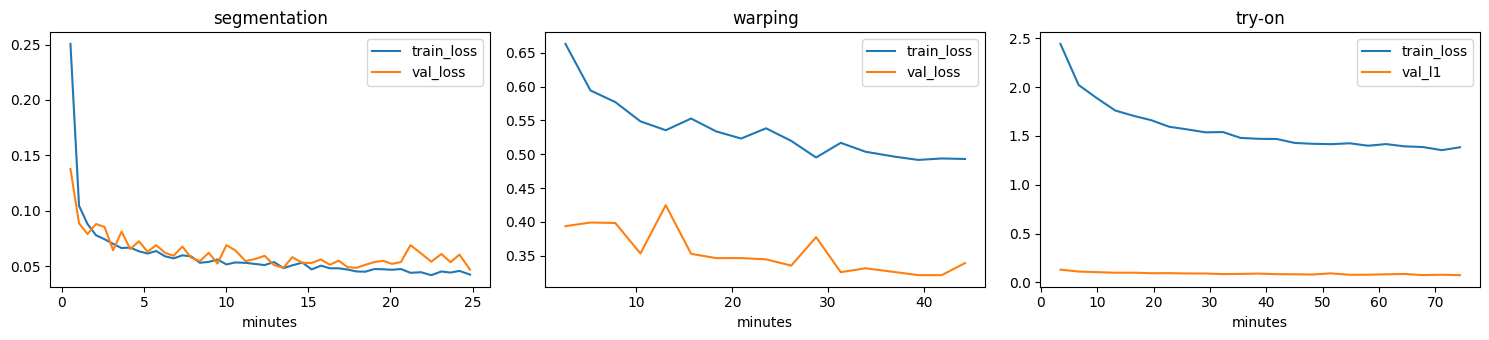

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, (nm, h, keys) in zip(ax, [('segmentation', seg_hist, ['train_loss', 'val_loss']),
                                 ('warping', warp_hist, ['train_loss', 'val_loss']),
                                 ('try-on', tom_hist, ['train_loss', 'val_l1'])]):
    h = pd.DataFrame(h)
    if h.empty: continue
    for k in keys: a.plot(h.minutes, h[k], label=k)
    a.set_title(nm); a.set_xlabel('minutes'); a.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/training_curves.png', dpi=120); plt.show()

In [18]:
def ssim(x, y):  # x,y in [0,1], (B,3,H,W)
    g = torch.exp(-(torch.arange(11, device=x.device) - 5.0) ** 2 / (2 * 1.5 ** 2)); g = (g / g.sum())
    k = (g[:, None] * g[None, :]).expand(3, 1, 11, 11)
    f = lambda t: F.conv2d(t, k, padding=5, groups=3)
    mx, my = f(x), f(y); sxx, syy, sxy = f(x * x) - mx ** 2, f(y * y) - my ** 2, f(x * y) - mx * my
    c1, c2 = 0.01 ** 2, 0.03 ** 2
    return (((2 * mx * my + c1) * (2 * sxy + c2)) / ((mx ** 2 + my ** 2 + c1) * (sxx + syy + c2))).mean((1, 2, 3))

import lpips
lp = lpips.LPIPS(net='alex', verbose=False).to(dev).eval()
TEST_IDS = np.arange(len(TE['names']))
_, seg_per = seg_miou(TE, TEST_IDS)
rows, w_iou, b_iou = [], [], []
with torch.no_grad():
    for bi in batches(TE, TEST_IDS):
        b = make_batch(TE, bi); final, rough, m, wc, wm = tryon(b)
        x, y = (final + 1) / 2, (b['person'] + 1) / 2
        s = ssim(x, y).cpu(); mse = ((x - y) ** 2).mean((1, 2, 3)).cpu(); l1 = (x - y).abs().mean((1, 2, 3)).cpu()
        lps = lp(final, b['person']).view(-1).cpu()
        w_iou.append(iou(wm, b['top'])); b_iou.append(iou(b['cmask'], b['top']))
        for j, i in enumerate(bi):
            rows.append(dict(name=TE['names'][i], ssim=float(s[j]), lpips=float(lps[j]), psnr=float(10 * torch.log10(1 / mse[j])), l1=float(l1[j])))
per_img = pd.DataFrame(rows); per_img.to_csv(f'{OUT}/test_per_image.csv', index=False)
scores = {
    'test photos': len(per_img),
    'segmentation mIoU': round(float(seg_per.mean()), 3),
    'warp IoU (ours)': round(float(torch.cat(w_iou).mean()), 3),
    'warp IoU (no warp)': round(float(torch.cat(b_iou).mean()), 3),
    'try-on SSIM': round(per_img.ssim.mean(), 3),
    'try-on LPIPS': round(per_img.lpips.mean(), 3),
    'try-on PSNR (dB)': round(per_img.psnr.mean(), 2),
    'try-on L1': round(per_img.l1.mean(), 4),
    'selected features': best_label,
}
json.dump(scores, open(f'{OUT}/scores.json', 'w'), indent=2)
display(pd.Series(scores).to_frame('value'))
display(pd.DataFrame({'class': CLASSES, 'test IoU': seg_per.round(3)}))

/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/homebrew/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


,value
test photos,1984
segmentation mIoU,0.92
warp IoU (ours),0.769
warp IoU (no warp),0.369
try-on SSIM,0.877
try-on LPIPS,0.108
try-on PSNR (dB),22.75
try-on L1,0.0271
selected features,F: agnostic + parts (no pose)


,class,test IoU
0,background,0.988
1,hair,0.904
2,face,0.940
3,neck,0.874
4,top,0.943
5,lower body,0.933
6,left arm,0.884
7,right arm,0.892


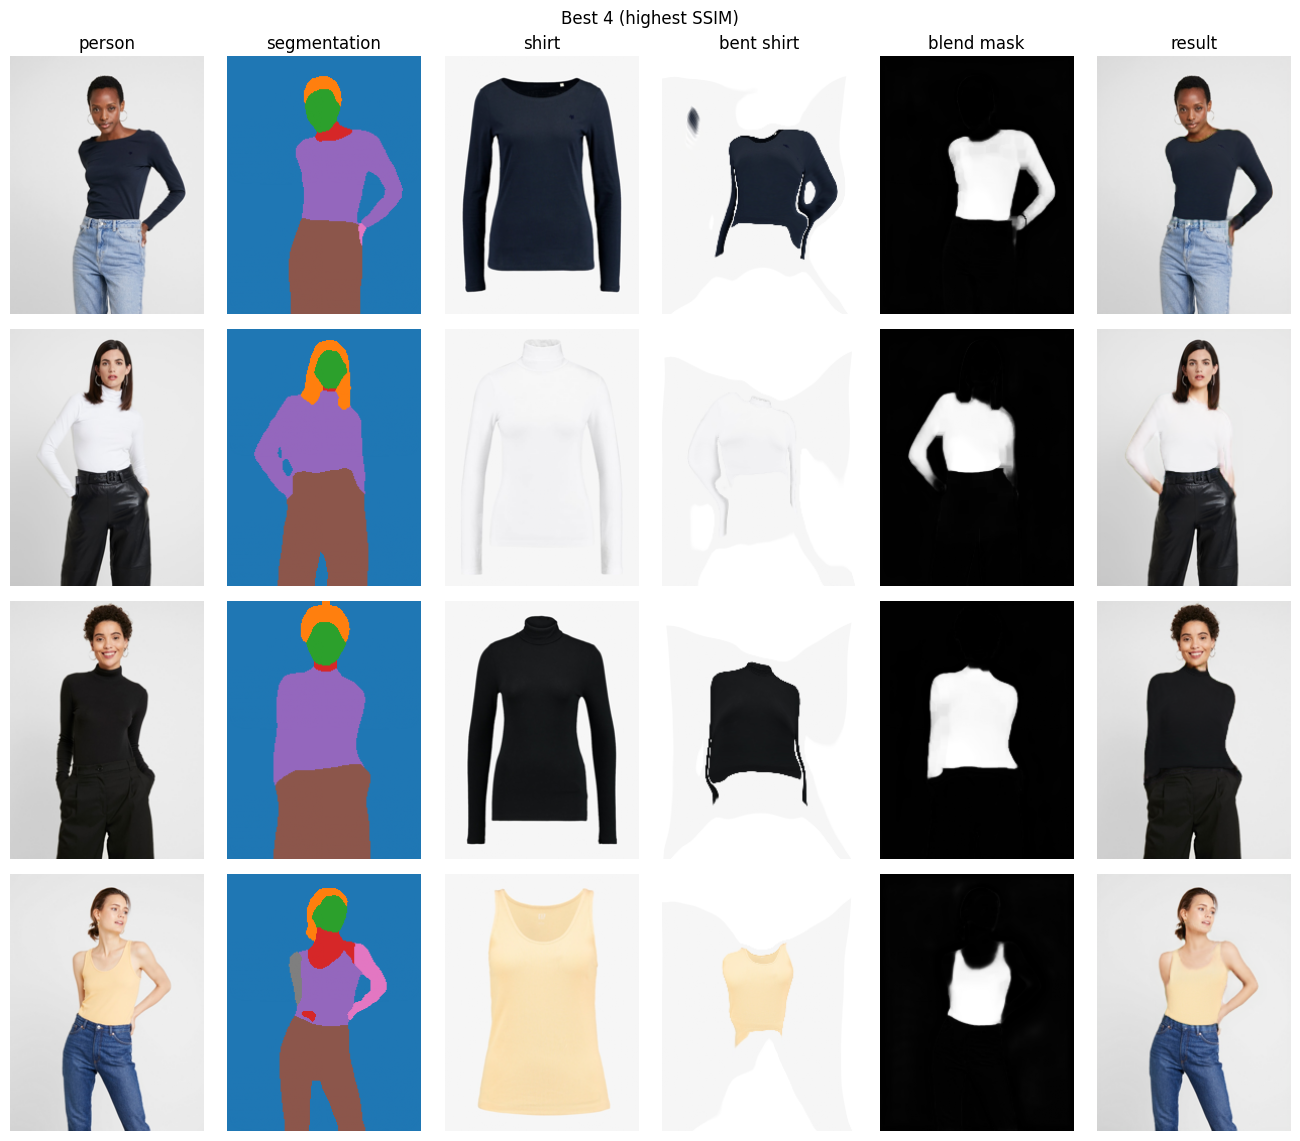

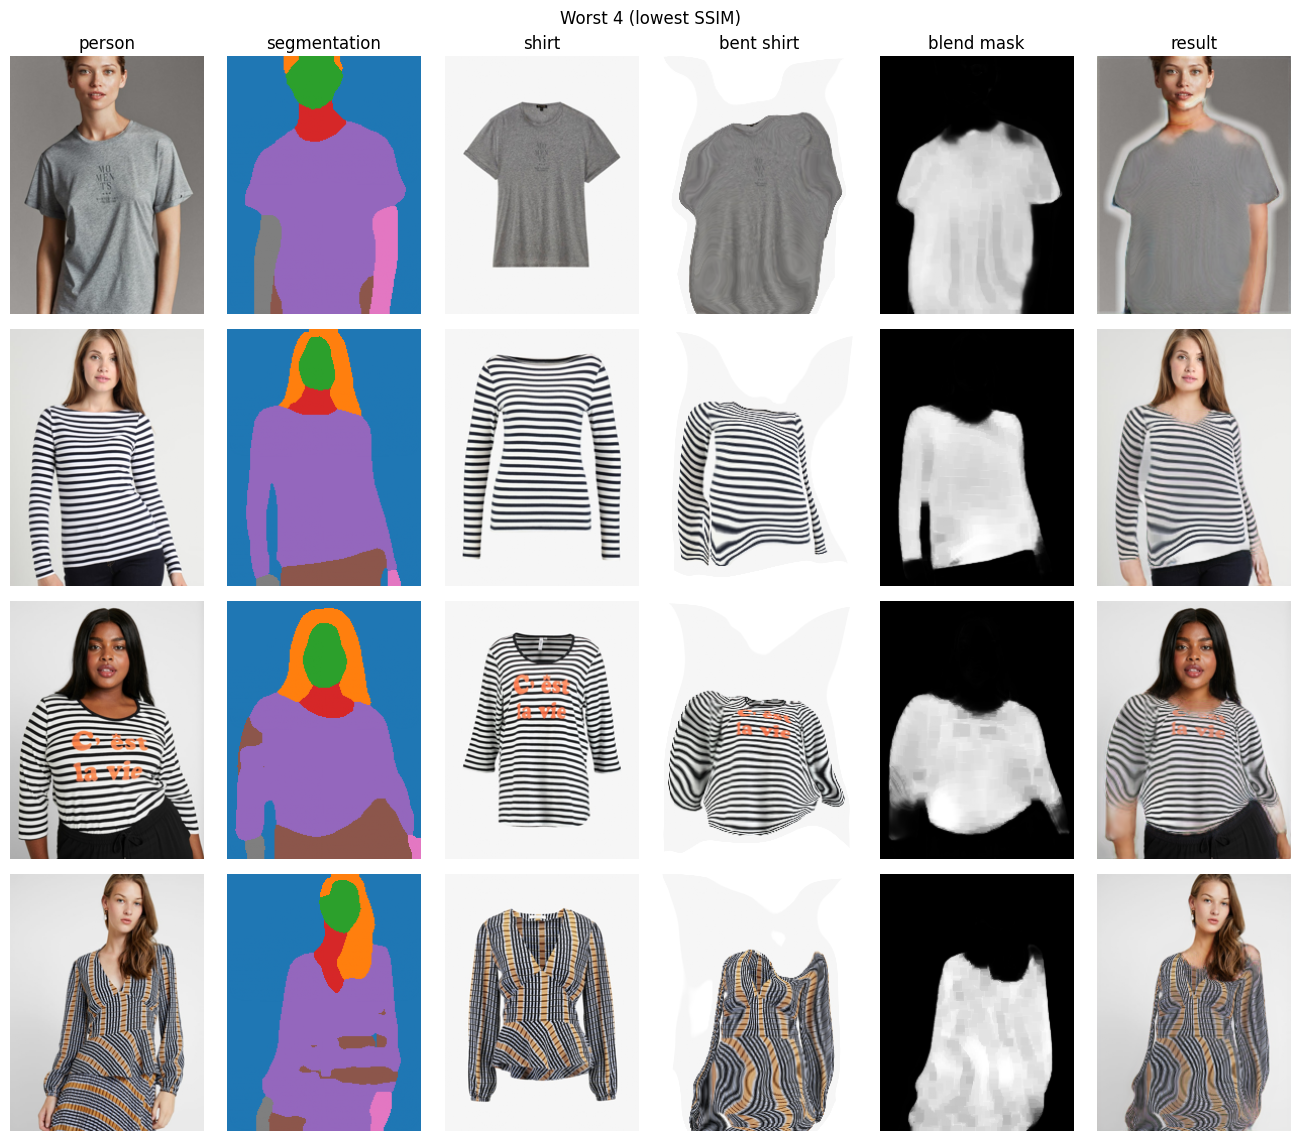

In [19]:
# paired results: real shirt on the same person (we can compare with the real photo)
def grid_show(D, ids, cloth_ids=None, fname=None, title=''):
    b = make_batch(D, ids)
    if cloth_ids is not None:
        c = make_batch(D, cloth_ids); b['cloth'], b['cmask'] = c['cloth'], c['cmask']
    with torch.no_grad():
        final, rough, m, wc, wm = tryon(b); segp = seg_forward(b['person']).argmax(1)
    cols = ['person', 'segmentation', 'shirt', 'bent shirt', 'blend mask', 'result']
    fig, ax = plt.subplots(len(ids), len(cols), figsize=(2.2 * len(cols), 2.9 * len(ids)))
    for i in range(len(ids)):
        imgs = [show(b['person'][i]), segp[i].cpu(), show(b['cloth'][i]), show(wc[i]), m[i, 0].cpu(), show(final[i])]
        for j, im in enumerate(imgs):
            a = ax[i, j]; a.imshow(im, cmap='tab10' if j == 1 else 'gray', vmin=0, vmax=9 if j == 1 else 1); a.axis('off')
            if i == 0: a.set_title(cols[j])
    fig.suptitle(title); plt.tight_layout()
    if fname: plt.savefig(f'{OUT}/{fname}', dpi=110)
    plt.show()

order = per_img.sort_values('ssim').index.values
grid_show(TE, order[-4:], fname='best4.png', title='Best 4 (highest SSIM)')
grid_show(TE, order[:4], fname='worst4.png', title='Worst 4 (lowest SSIM)')

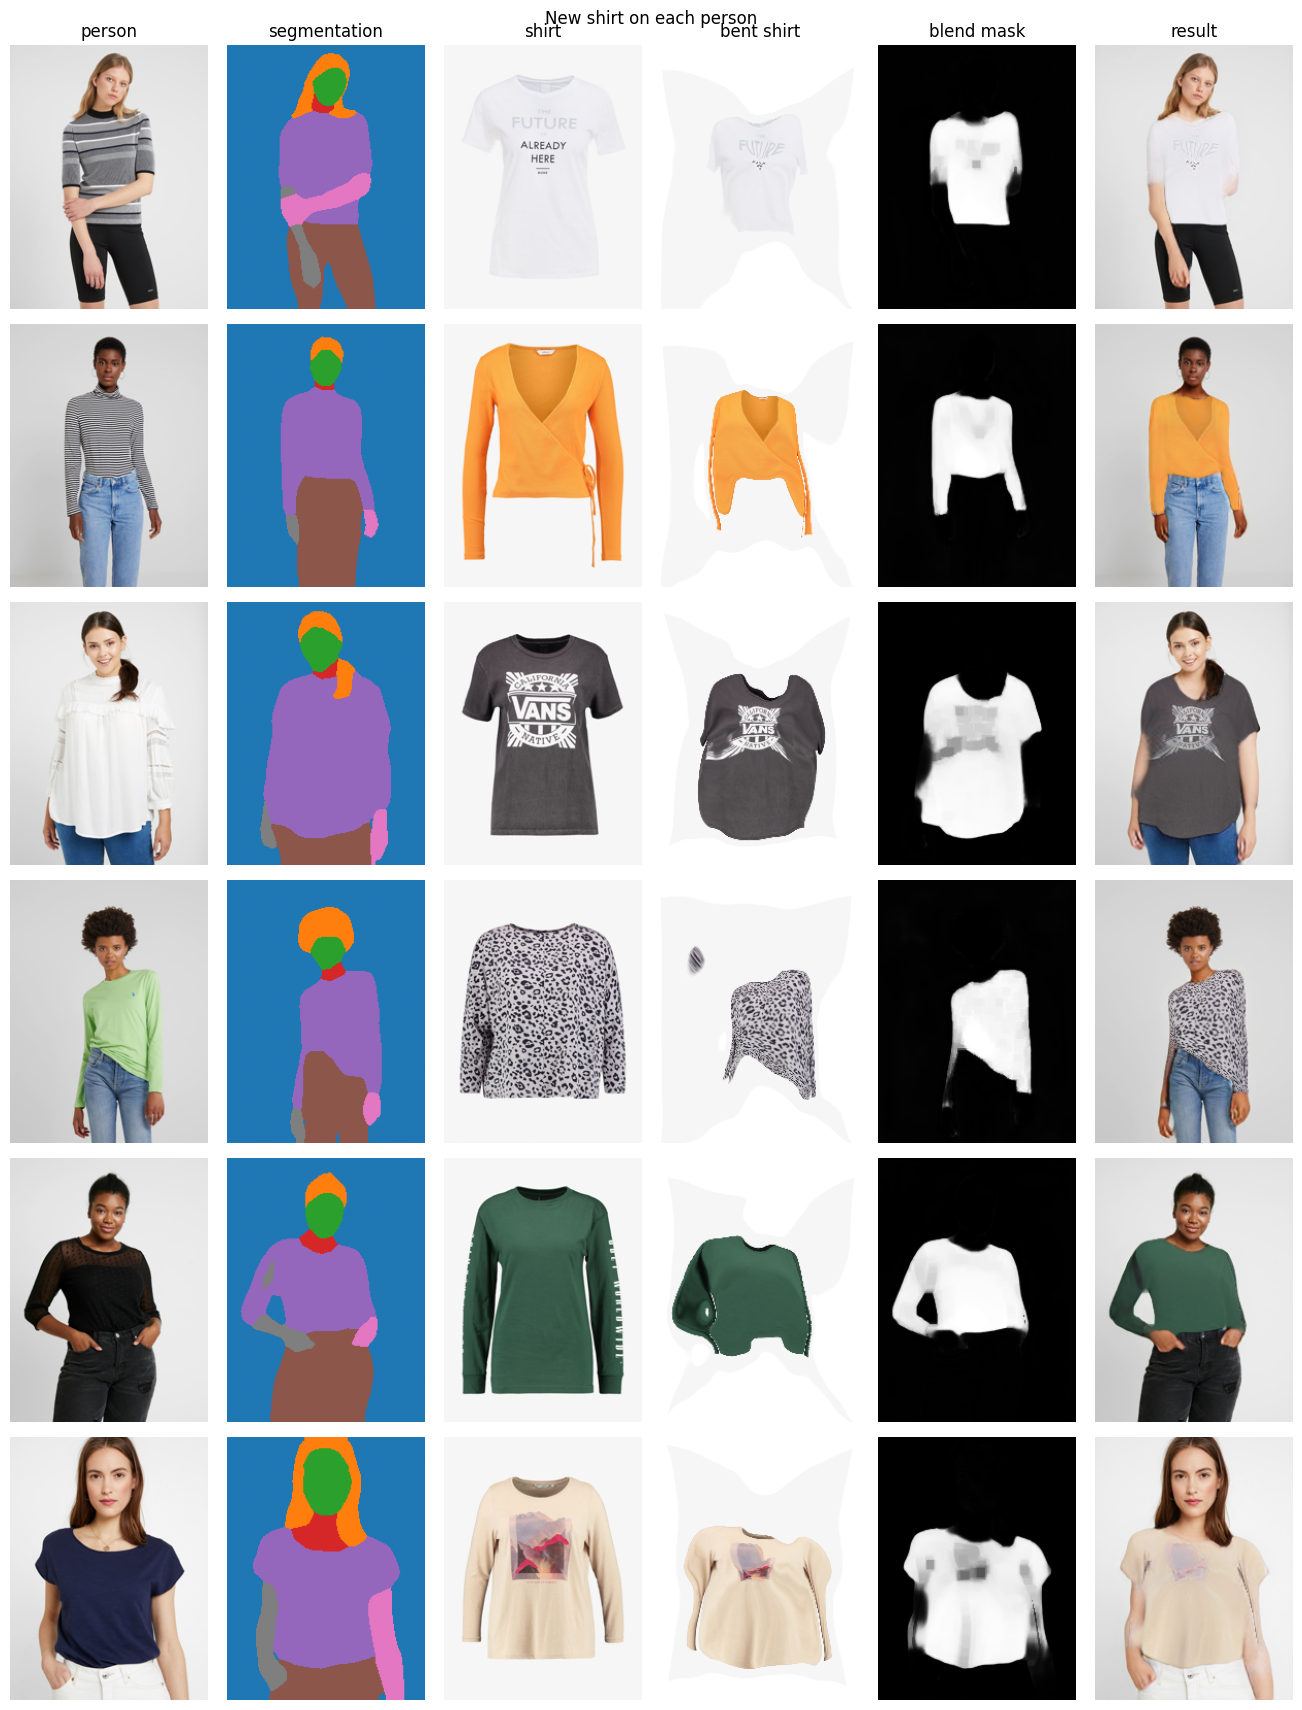

In [20]:
# unpaired results: a different shirt on each person (the real use case)
rng = np.random.RandomState(1)
people = rng.choice(TEST_IDS, 6, replace=False); shirts = rng.choice(TEST_IDS, 6, replace=False)
grid_show(TE, people, shirts, fname='new_shirts.png', title='New shirt on each person')

1937 unpaired test pairs ranked; top-6 realism scores: [1.55 1.53 1.42 1.41 1.38 1.37]


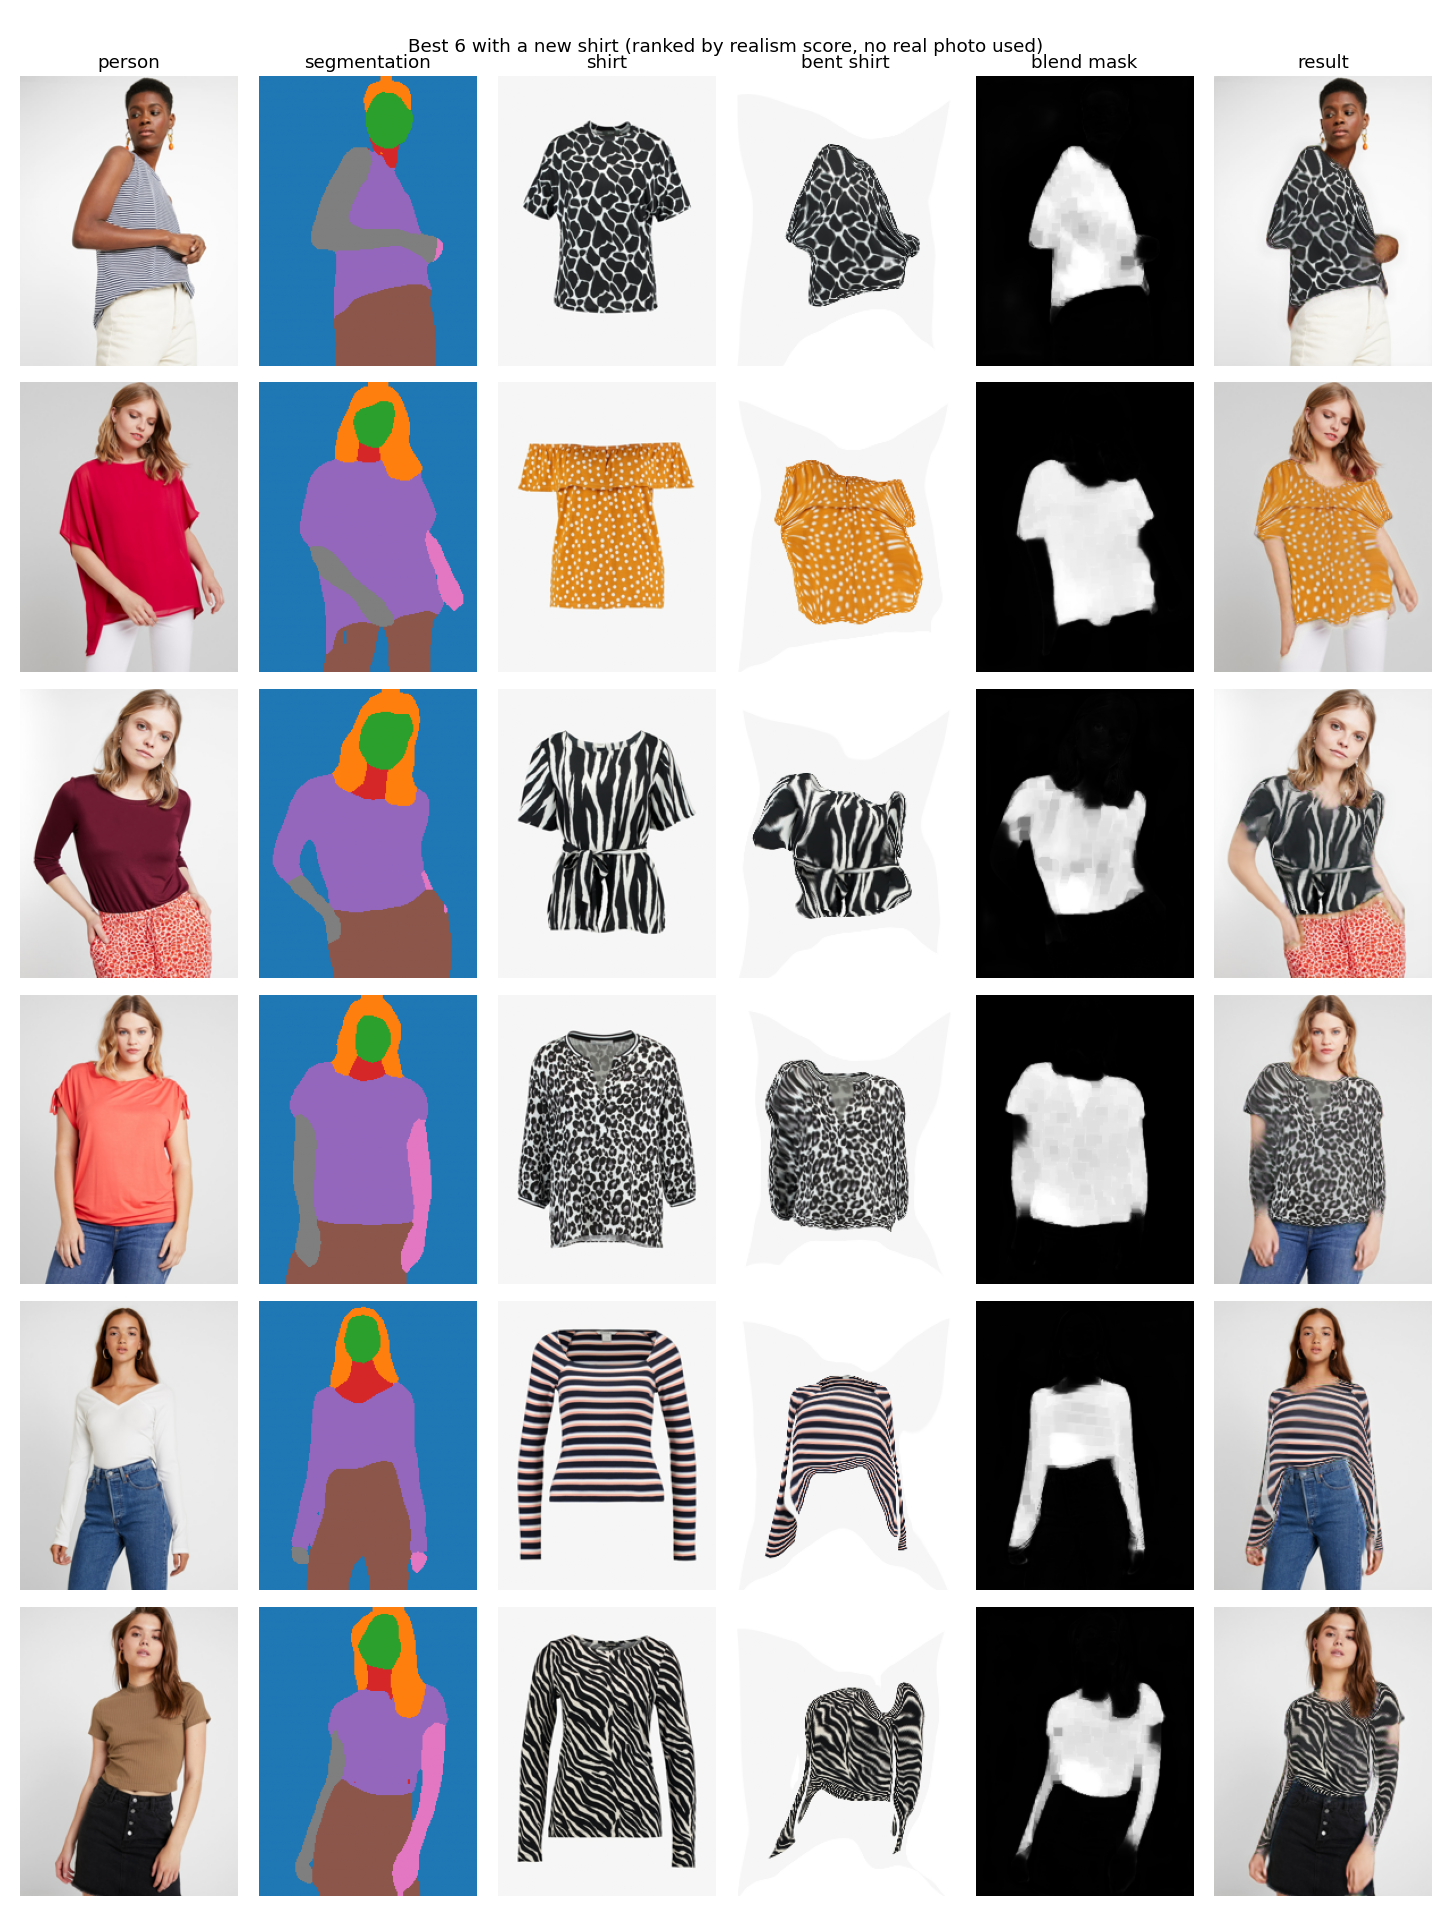

In [ ]:
# best results with a NEW shirt (the real use case: there is no real photo to compare with)
# rank the official unpaired test pairs by the discriminator's realism score (higher = looks more real)
pos = {n: i for i, n in enumerate(TE['names'])}
pairs_file = os.path.join(DATA_ROOT, 'test_pairs.txt')
up = [l.split() for l in open(pairs_file)] if os.path.exists(pairs_file) else []
up = np.array([(pos[a], pos[c]) for a, c in up if a in pos and c in pos and a != c])
disc.eval(); real_score = []
with torch.no_grad():
    for k in range(0, len(up), 16):
        pp = up[k:k + 16]; b = make_batch(TE, pp[:, 0]); c = make_batch(TE, pp[:, 1])
        b['cloth'], b['cmask'] = c['cloth'], c['cmask']
        out = tryon(b)[0]
        real_score += disc(torch.cat([stack(b, FEATS), out], 1)).mean((1, 2, 3)).cpu().tolist()
real_score = np.array(real_score)
top = up[np.argsort(-real_score)[:6]]
print(f'{len(up)} unpaired test pairs ranked; top-6 realism scores:', np.sort(real_score)[::-1][:6].round(2))
grid_show(TE, top[:, 0], top[:, 1], fname='best_new_shirts.png',
          title='Best 6 with a new shirt (ranked by realism score, no real photo used)')

In [21]:
# FID / KID on the official unpaired test list (each person gets a different shirt)
import torch_fidelity
pos = {n: i for i, n in enumerate(TE['names'])}
pairs_file = os.path.join(DATA_ROOT, 'test_pairs.txt')
pairs = [l.split() for l in open(pairs_file)] if os.path.exists(pairs_file) else []
pairs = [(pos[a], pos[c]) for a, c in pairs if a in pos and c in pos]
if len(pairs) < 10:   # no list: make a shuffled one
    perm = np.random.RandomState(2).permutation(len(TEST_IDS)); pairs = list(zip(TEST_IDS, perm))
fake_dir, real_dir = f'{OUT}/unpaired', f'{OUT}/real'
os.makedirs(fake_dir, exist_ok=True); os.makedirs(real_dir, exist_ok=True)
with torch.no_grad():
    for k in range(0, len(pairs), 16):
        pp = np.array(pairs[k:k + 16]); b = make_batch(TE, pp[:, 0]); c = make_batch(TE, pp[:, 1])
        b['cloth'], b['cmask'] = c['cloth'], c['cmask']
        out = tryon(b)[0]
        for j in range(len(pp)):
            Image.fromarray((show(out[j]) * 255).astype(np.uint8)).save(f'{fake_dir}/{k + j:05d}.png')
for i in TEST_IDS:
    Image.fromarray(np.asarray(TE['person'][i])).save(f'{real_dir}/{i:05d}.png')
fm = torch_fidelity.calculate_metrics(input1=fake_dir, input2=real_dir, fid=True, kid=True, cuda=False, verbose=False, save_cpu_ram=True,
                                      kid_subset_size=min(1000, len(pairs) // 2))
scores['unpaired FID'] = round(fm['frechet_inception_distance'], 2)
scores['unpaired KID x100'] = round(100 * fm['kernel_inception_distance_mean'], 3)
json.dump(scores, open(f'{OUT}/scores.json', 'w'), indent=2)
display(pd.Series(scores).to_frame('value'))

,value
test photos,1984
segmentation mIoU,0.92
warp IoU (ours),0.769
warp IoU (no warp),0.369
try-on SSIM,0.877
try-on LPIPS,0.108
try-on PSNR (dB),22.75
try-on L1,0.0271
selected features,F: agnostic + parts (no pose)
unpaired FID,13.24


## 9b. Fully automatic pipeline (no label maps from the dataset)

Feature selection chose inputs that need **no pose points**. So the only thing the try-on needs besides the photo is the body-part map, and our segmentation model (model 1) can make that.

Here we throw away the dataset's label maps, let model 1 predict them, and score the try-on again. This is how the system would work on a new photo.

In [22]:
def batch_auto(D, ids, cloth_ids=None):
    ids = np.asarray(ids)
    small = {k: np.asarray(D[k][ids]) for k in ['person', 'cloth', 'cmask', 'parse', 'pose']}
    if cloth_ids is not None:
        small['cloth'], small['cmask'] = np.asarray(D['cloth'][cloth_ids]), np.asarray(D['cmask'][cloth_ids])
    b = make_batch(small, np.arange(len(ids)))
    with torch.no_grad():
        small['parse'] = seg_forward(b['person']).argmax(1).cpu().numpy().astype(np.uint8)
    return make_batch(small, np.arange(len(ids)))

auto_rows = []
with torch.no_grad():
    for bi in batches(TE, TEST_IDS):
        b = batch_auto(TE, bi); final = tryon(b)[0]
        x, y = (final + 1) / 2, (b['person'] + 1) / 2
        s_, lps = ssim(x, y).cpu(), lp(final, b['person']).view(-1).cpu()
        auto_rows += [dict(ssim=float(s_[j]), lpips=float(lps[j])) for j in range(len(bi))]
auto = pd.DataFrame(auto_rows)
scores['auto pipeline SSIM'] = round(auto.ssim.mean(), 3)
scores['auto pipeline LPIPS'] = round(auto.lpips.mean(), 3)
json.dump(scores, open(f'{OUT}/scores.json', 'w'), indent=2)
display(pd.DataFrame({'label maps from dataset': [scores['try-on SSIM'], scores['try-on LPIPS']],
                      'label maps from our model 1': [scores['auto pipeline SSIM'], scores['auto pipeline LPIPS']]},
                     index=['SSIM (higher better)', 'LPIPS (lower better)']))

,label maps from dataset,label maps from our model 1
SSIM (higher better),0.877,0.873
LPIPS (lower better),0.108,0.111


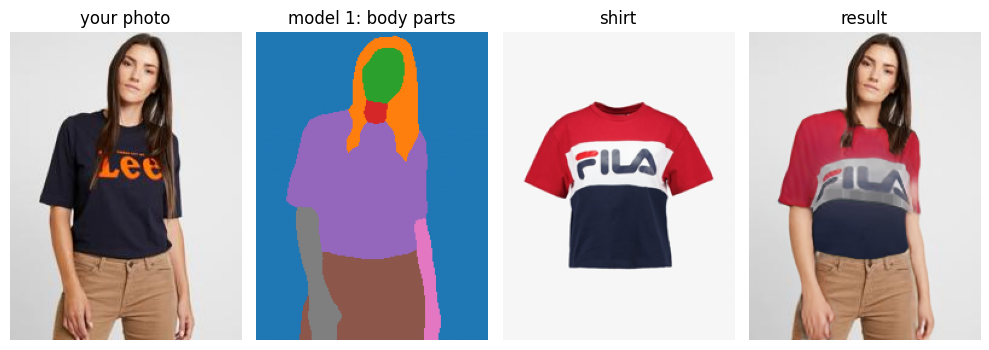

In [23]:
# try it on any photo file (front-facing person, plain background works best)
def run_on_photo(path, shirt_i):
    im = Image.open(path).convert('RGB'); w, h = im.size
    if h / w > 4 / 3: nh = int(w * 4 / 3); im = im.crop((0, (h - nh) // 2, w, (h - nh) // 2 + nh))
    else: nw = int(h * 3 / 4); im = im.crop(((w - nw) // 2, 0, (w - nw) // 2 + nw, h))
    D = {'person': np.asarray(im.resize((W, H), Image.BICUBIC))[None], 'cloth': TE['cloth'][shirt_i][None],
         'cmask': TE['cmask'][shirt_i][None], 'parse': np.zeros((1, H, W), np.uint8), 'pose': np.zeros((1, NK, 3), np.float32)}
    b = batch_auto(D, [0])
    with torch.no_grad(): final = tryon(b)[0]
    fig, ax = plt.subplots(1, 4, figsize=(10, 3.6))
    for a, im_, t in zip(ax, [show(b['person'][0]), b['parse'][0].cpu(), show(b['cloth'][0]), show(final[0])],
                         ['your photo', 'model 1: body parts', 'shirt', 'result']):
        a.imshow(im_, cmap='tab10', vmin=0, vmax=9); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

# example with a test photo saved as a file
Image.fromarray(np.asarray(TE['person'][7 % len(TEST_IDS)])).save(f'{OUT}/example_photo.jpg')
run_on_photo(f'{OUT}/example_photo.jpg', 21 % len(TEST_IDS))

In [24]:
# before / after, next to published results at the same size (VITON-HD paper, Table 1)
v1_path = f'{OUT}/scores_v1.json'
cmp = pd.DataFrame({
    'CP-VTON': [0.739, 0.159, 56.23], 'ACGPN': [0.842, 0.064, 26.45], 'VITON-HD': [0.844, 0.062, 27.83],
}, index=['SSIM (higher better)', 'LPIPS (lower better)', 'FID (lower better)'])
if os.path.exists(v1_path):
    v1 = json.load(open(v1_path))
    cmp['ours, step 8'] = [v1['try-on SSIM'], v1['try-on LPIPS'], v1.get('unpaired FID')]
cmp['ours, step 8b'] = [scores['try-on SSIM'], scores['try-on LPIPS'], scores.get('unpaired FID')]
display(cmp)
print(f'FID: we compute it on our own {len(TEST_IDS)} test photos with torch-fidelity, so compare it loosely.')

,CP-VTON,ACGPN,VITON-HD,"ours, step 8","ours, step 8b"
SSIM (higher better),0.739,0.842,0.844,0.870,0.877
LPIPS (lower better),0.159,0.064,0.062,0.131,0.108
FID (lower better),56.230,26.450,27.830,17.970,13.240


FID: we compute it on our own 1984 test photos with torch-fidelity, so compare it loosely.


## 10. Demo

Pick a test person and any shirt from the test set. The models run on the Mac in well under a second.

In [ ]:
def demo(person_i, shirt_i):
    b = make_batch(TE, np.array([person_i])); c = make_batch(TE, np.array([shirt_i]))
    b['cloth'], b['cmask'] = c['cloth'], c['cmask']
    t0 = time.time()
    with torch.no_grad(): final = tryon(b)[0]
    if dev.type == 'mps': torch.mps.synchronize()
    ms = (time.time() - t0) * 1000
    fig, ax = plt.subplots(1, 3, figsize=(8, 4))
    for a, im, t in zip(ax, [b['person'][0], c['cloth'][0], final[0]], ['person', 'shirt', f'result ({ms:.0f} ms)']):
        a.imshow(show(im)); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

demo(0, 5)
try:
    import ipywidgets as wdg
    n = len(TE['names']) - 1
    wdg.interact(demo, person_i=wdg.IntSlider(0, 0, n), shirt_i=wdg.IntSlider(5, 0, n))
except ImportError:
    print('pip install ipywidgets for sliders')

## Summary

- **Cleaning** removed rows with missing or broken files, bad masks, no visible top, bad pose, duplicate shirts and test shirts that also appear in train.
- **Preprocessing** resized everything to 256×192, merged labels into 8 classes and stored them as arrays for fast training.
- **Feature selection** compared 6 input sets for the warping model. The best set is used for both the warping and try-on models.
- **3 models** trained on a MacBook Air M4 (Apple GPU): segmentation, warping, try-on.
- **Step 8b** made the try-on sharper: known pixels kept from the photo, plus a PatchGAN loss, best checkpoint picked by validation LPIPS. Small holes in the blend mask are filled so prints come from the real shirt photo.
- **Limits:** low size (256×192), short training time, and the dataset has only women wearing tops.